In [19]:
%load_ext autoreload
%autoreload 2
from osnap import odb, viz
from osnap.config import CONFIG
import numpy as np
import astropy
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
from scipy.interpolate import interp1d
import yt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [20]:
data = odb.ODB("/mnt/home/jdelker/test1.odb", reset = True)
data.load_progenitor("kepler", "/mnt/home/jdelker/test_osnap_project/s12.0_presn")
data.load_collapse("stir", "/mnt/research/SNAPhU/STIR/run_sukhbold/run_14may19_a1.25/run_12.0/output/stir2_14may19_s12.0_alpha1.25_hdf5_chk_0197")
data.generate_tracers("stir", "/mnt/research/SNAPhU/STIR/run_sukhbold/run_14may19_a1.25/run_12.0/output/", "stir2_14may19_s12.0_alpha1.25", num_tracers = 1000)

Loading 'kepler' progenitor data from '/mnt/home/jdelker/test_osnap_project/s12.0_presn'
Loading 'kepler' data from '/mnt/home/jdelker/test_osnap_project/s12.0_presn'


Converting enclosed_mass from g to solMass.
Converting specific_entropy from erg / (K g) to k_B / baryon.
Error: Could not convert specific_entropy from erg / (K g) to k_B / baryon.
Converting grav_potential from m3 g / (cm kg s2) to erg / g.
Loading 'stir' collapse data from '/mnt/research/SNAPhU/STIR/run_sukhbold/run_14may19_a1.25/run_12.0/output/stir2_14may19_s12.0_alpha1.25_hdf5_chk_0197'
Loading 'stir' data from '/mnt/research/SNAPhU/STIR/run_sukhbold/run_14may19_a1.25/run_12.0/output/stir2_14may19_s12.0_alpha1.25_hdf5_chk_0197'
Converting enclosed_mass from g to solMass.
Loading 'stir' tracer data from '/mnt/research/SNAPhU/STIR/run_sukhbold/run_14may19_a1.25/run_12.0/output/'
Loading 'stir' data from '/mnt/research/SNAPhU/STIR/run_sukhbold/run_14may19_a1.25/run_12.0/output/stir2_14may19_s12.0_alpha1.25_hdf5_chk_0197'
Converting enclosed_mass from g to solMass.


In [ ]:
data = odb.ODB("/mnt/home/jdelker/test1.odb")
new_volumes = data.read("profiles", "cell_volume")
viz.plot_profile(data, "profiles", "cell_volume", x_axis = "radius", log_y = True)
viz.plot_profile(data, "profiles", "radius", x_axis = "radius", log_y = False)
viz.plot_profile(data, "progenitor", "specific_entropy", x_axis = "radius", log_x = True, log_y = True)

In [17]:
data = odb.ODB("/mnt/home/jdelker/test1.odb")
radii = data.read("profiles", "radius")
radii.shifted("inner")

fine_zones: [0.000e+00 5.000e-01 1.000e+00 ... 9.915e+02 9.920e+02 9.925e+02]
coords_interp: [0.000e+00 5.000e-01 1.000e+00 ... 9.915e+02 9.920e+02 9.925e+02]


<Variable [0.00000000e+00, 2.44140625e+04, 4.88281250e+04, 7.32421875e+04,
           9.76562500e+04, 1.22070312e+05, 1.46484375e+05, 1.70898438e+05,
           1.95312500e+05, 2.19726562e+05, 2.44140625e+05, 2.68554688e+05,
           2.92968750e+05, 3.17382812e+05, 3.41796875e+05, 3.66210938e+05,
           3.90625000e+05, 4.15039062e+05, 4.39453125e+05, 4.63867188e+05,
           4.88281250e+05, 5.12695312e+05, 5.37109375e+05, 5.61523438e+05,
           5.85937500e+05, 6.10351562e+05, 6.34765625e+05, 6.59179688e+05,
           6.83593750e+05, 7.08007812e+05, 7.32421875e+05, 7.56835938e+05,
           7.81250000e+05, 8.05664062e+05, 8.30078125e+05, 8.54492188e+05,
           8.78906250e+05, 9.03320312e+05, 9.27734375e+05, 9.52148438e+05,
           9.76562500e+05, 1.00097656e+06, 1.02539062e+06, 1.04980469e+06,
           1.07421875e+06, 1.09863281e+06, 1.12304688e+06, 1.14746094e+06,
           1.17187500e+06, 1.19628906e+06, 1.22070312e+06, 1.24511719e+06,
           1.26953125e+06

[]

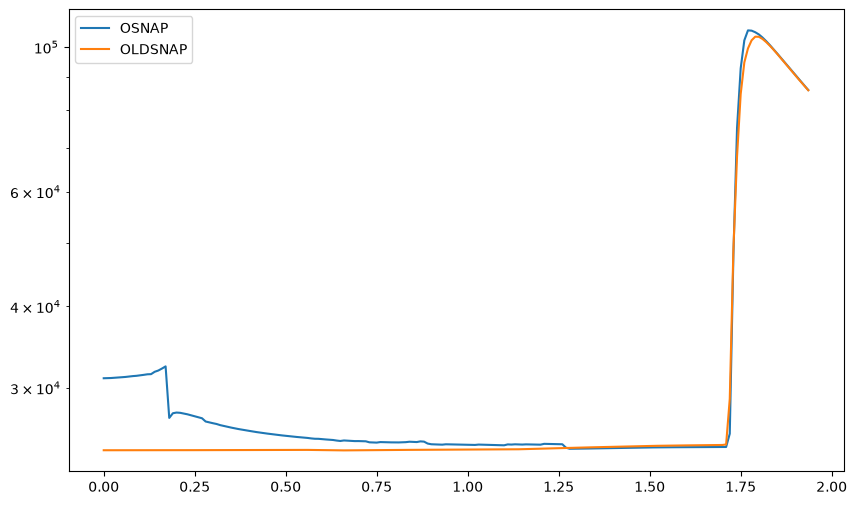

In [68]:
#viz.plot_profile(data, "tracers", "density", x_axis = "radius", log_x = True, log_y = True)
x_data = data.read("tracers", "time")
y_data = data.read("tracers", "density")
xr_data = xr.open_dataset("/mnt/home/jdelker/test_osnap_project/run_12.0_stir2_14may19_s12.0_alpha1.25_tracers.nc")

plt.figure(figsize=(10, 6))
plt.plot(x_data, y_data[:, -100], label = "OSNAP")
plt.plot(xr_data["time"], xr_data["dens"][:, -100], label = "OLDSNAP")
plt.legend()
plt.semilogy()

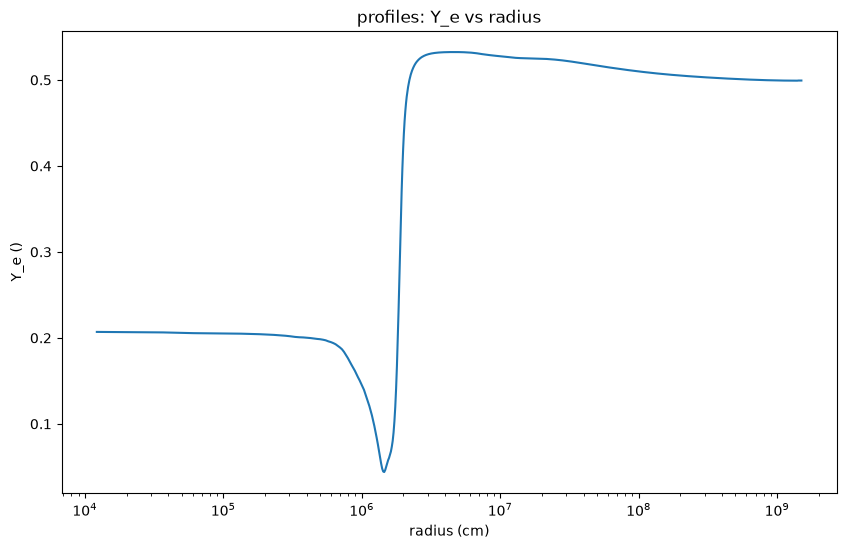

In [10]:

viz.plot_profile(data, "profiles", "Y_e", x_axis = "radius", log_x = True, log_y = False)


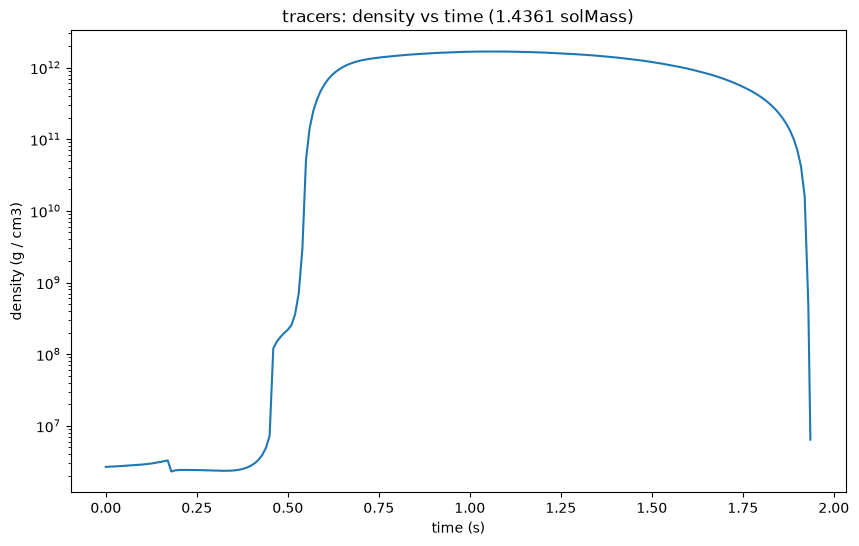

In [65]:
viz.plot_tracers(data, "density", log_y = True, zone = 0)

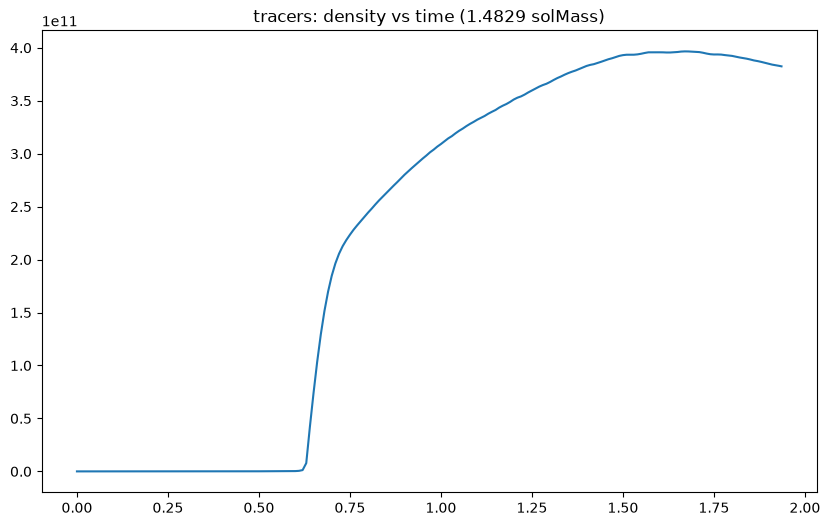

In [66]:
import xarray as xr
import matplotlib.pyplot as plt
zone = 0
xr_data = xr.open_dataset("/mnt/home/jdelker/test_osnap_project/run_12.0_stir2_14may19_s12.0_alpha1.25_tracers.nc")
plt.figure(figsize=(10, 6))
plt.title(f"tracers: density vs time ({xr_data['mass'].values[zone]:.4f} solMass)")
plt.plot(xr_data["time"], xr_data["dens"][:, zone])

OSNAP radius range: 12207.03125 - 1496875000.0
OLD_SNAP radius range: 24414.0625 - 1494866931.2040567


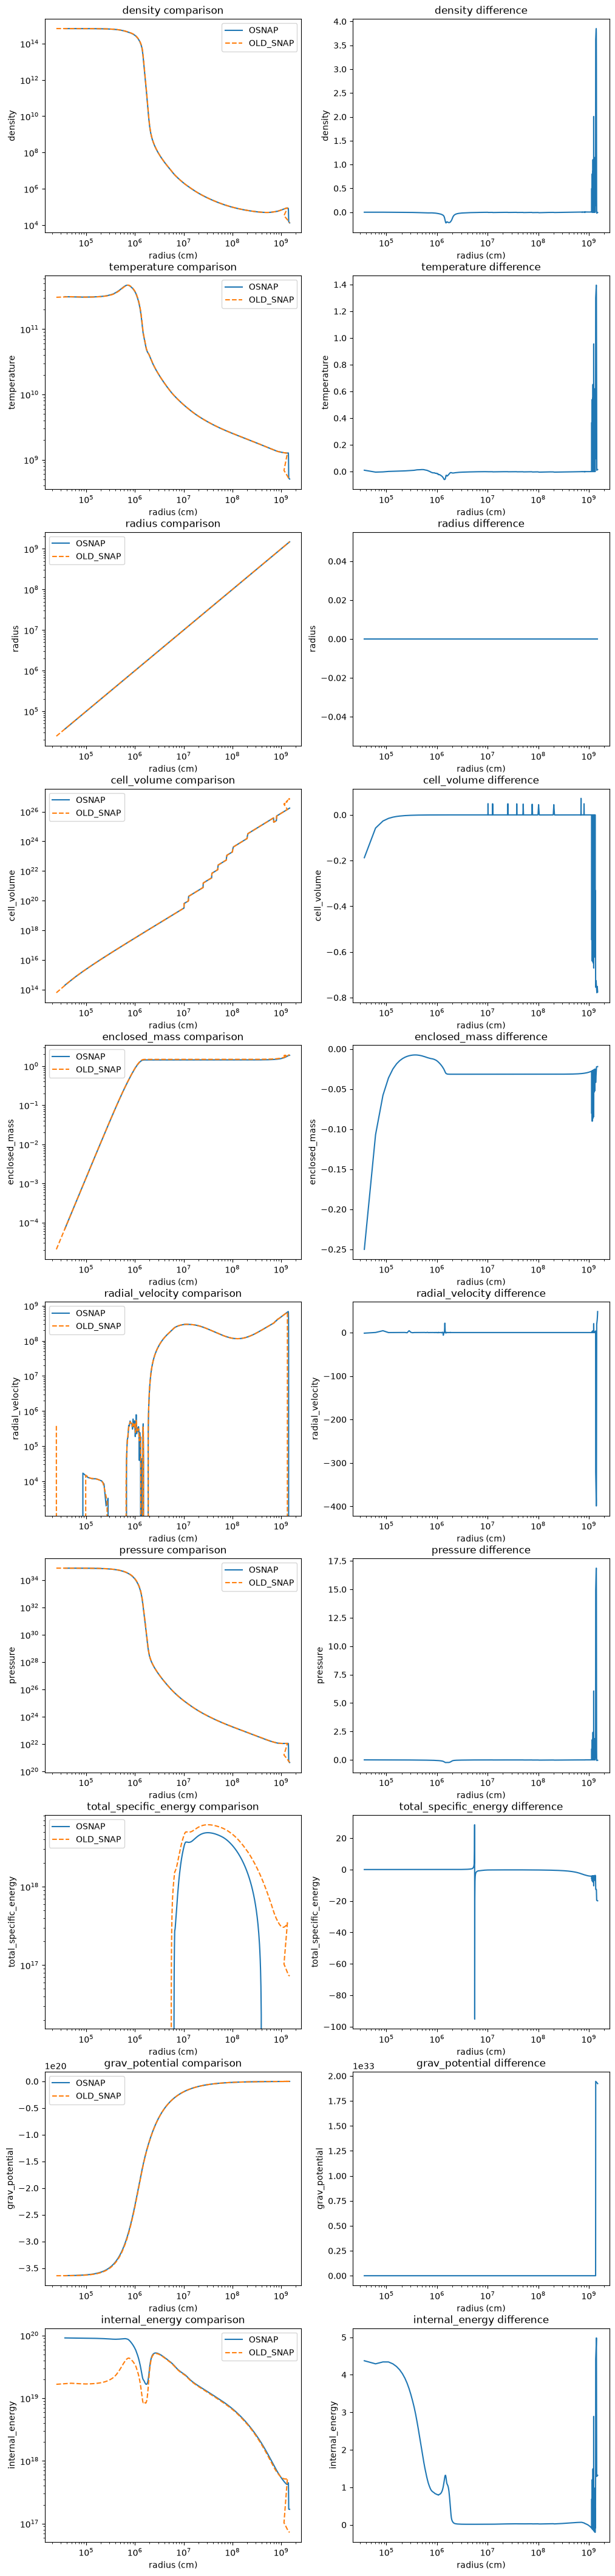

In [ ]:
data = odb.ODB("/mnt/home/jdelker/test1.odb")
old_data = pd.read_csv("/mnt/home/jdelker/old_snap/data/stitched_output/stitched_stir2_14may19_s12.0_alpha1.25_n1000", sep="\s+")

name_sets = [["density", "density", True, True],
         ["temperature", "temp", True, True],
         ["radius", "r", True, True],
         ["cell_volume", "cell_volume", True, True],
         ["enclosed_mass", "enclosed_mass", True, True],
         ["radial_velocity", "v", True, True],
         ["pressure", "pressure", True, True],
         ["total_specific_energy", "total_specific_energy", True, True],
         ["grav_potential", "gpot", True, False],
         ["internal_energy", "ener", True, True]]

osnap_radius = data.read("profiles", "radius").value
old_radius = old_data["r"].values
old_radius = old_radius[(old_radius >= osnap_radius.min()) & (old_radius <= osnap_radius.max())]
print(f"OSNAP radius range: {osnap_radius.min()} - {osnap_radius.max()}")
print(f"OLD_SNAP radius range: {old_radius.min()} - {old_radius.max()}")
old_data = old_data[old_data["r"].isin(old_radius)]

osnap_radius_adj = osnap_radius[(osnap_radius >= old_radius.min()) & (osnap_radius <= old_radius.max())]

plt.figure(figsize=(12, 54))
for i in range(len(name_sets)):
    name_set = name_sets[i]
    osnap_data = data.read("profiles", name_set[0]).value
    osnap_data = osnap_data[(osnap_radius >= old_radius.min()) & (osnap_radius <= old_radius.max())]
    
    plt.subplot(10, 2, (i * 2) + 1)
    plt.title(f"{name_set[0]} comparison")
    plt.plot(osnap_radius_adj, osnap_data, label = "OSNAP")
    plt.plot(old_radius, old_data[name_set[1]].values, "--", label = "OLD_SNAP")
    plt.xlabel("radius (cm)")
    plt.ylabel(name_set[0])
    plt.legend()
    
    if name_set[2]:
        plt.xscale("log")
    if name_set[3]:
        plt.yscale("log")
    
    plt.subplot(10, 2, (i * 2) + 2)
    plt.title(f"{name_set[0]} difference")
    interp_func = interp1d(old_radius, old_data[name_set[1]].values)
    values = interp_func(osnap_radius_adj)
    plt.plot(osnap_radius_adj, (osnap_data - values) / values)
    plt.xlabel("radius (cm)")
    plt.ylabel##)
    plt.semilogx()

plt.show()


In [ ]:
import h5py
from scipy.interpolate import RegularGridInterpolator
from astropy import units as u, constants as const
from osnap.config import CONFIG

def test_calculate_total_specific_energy(old_method, ye, temp, dens, vel, gpot):
    
    # Load the equation of state as an interpolator
    with h5py.File(CONFIG["EOS_PATH"], 'r') as EOS:
        logenergy = RegularGridInterpolator((EOS['ye'], EOS['logtemp'], EOS['logrho']), 
                                                EOS['logenergy'][:,:,:], bounds_error = False)
        
        # The EOS offsets its energy values by a constant energy_shift to ensure no values are negative.
        # So, we need to offset it back down by the same amount to get the correct total specific energy.
        #energy_shift = EOS['energy_shift'][0] * u.erg / u.g

    # Use the EOS to calculate the total specific energy
    llogtemp = np.log10((temp * const.k_B.to(u.MeV / u.K)).value)
    llogrho = np.log10(dens)
    energy = 10.0 ** logenergy(np.array([ye, llogtemp, llogrho]).T) * u.erg / u.g
    energy0 = 10.0 ** logenergy(np.array([ye, llogtemp * 0.0 - 2.0, llogrho]).T) * u.erg / u.g

    # Calculate the total specific energy and return it as a Variable
    if old_method:
        ener = 0.5 * (vel * u.cm / u.s) ** 2 + (energy - energy0)# - energy_shift
    else:
        ener = 0.5 * (vel * u.cm / u.s) ** 2 + (energy - energy0) + (gpot * u.erg / u.g)# - energy_shift
    return ener

yt : [WARNING  ] 2026-11-23 12:18:06,991 Extending phi dimension to 2PI + left edge.
yt : [WARNING  ] 2026-11-23 12:18:06,991 Extending theta dimension to PI + left edge.
yt : [INFO     ] 2026-11-23 12:18:07,018 Parameters: current_time              = 1.935693984283133
yt : [INFO     ] 2026-11-23 12:18:07,018 Parameters: domain_dimensions         = [240   1   1]
yt : [INFO     ] 2026-11-23 12:18:07,019 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-11-23 12:18:07,019 Parameters: domain_right_edge         = [1.50000000e+09 3.14159265e+00 6.28318531e+00]
yt : [INFO     ] 2026-11-23 12:18:07,019 Parameters: cosmological_simulation   = 0


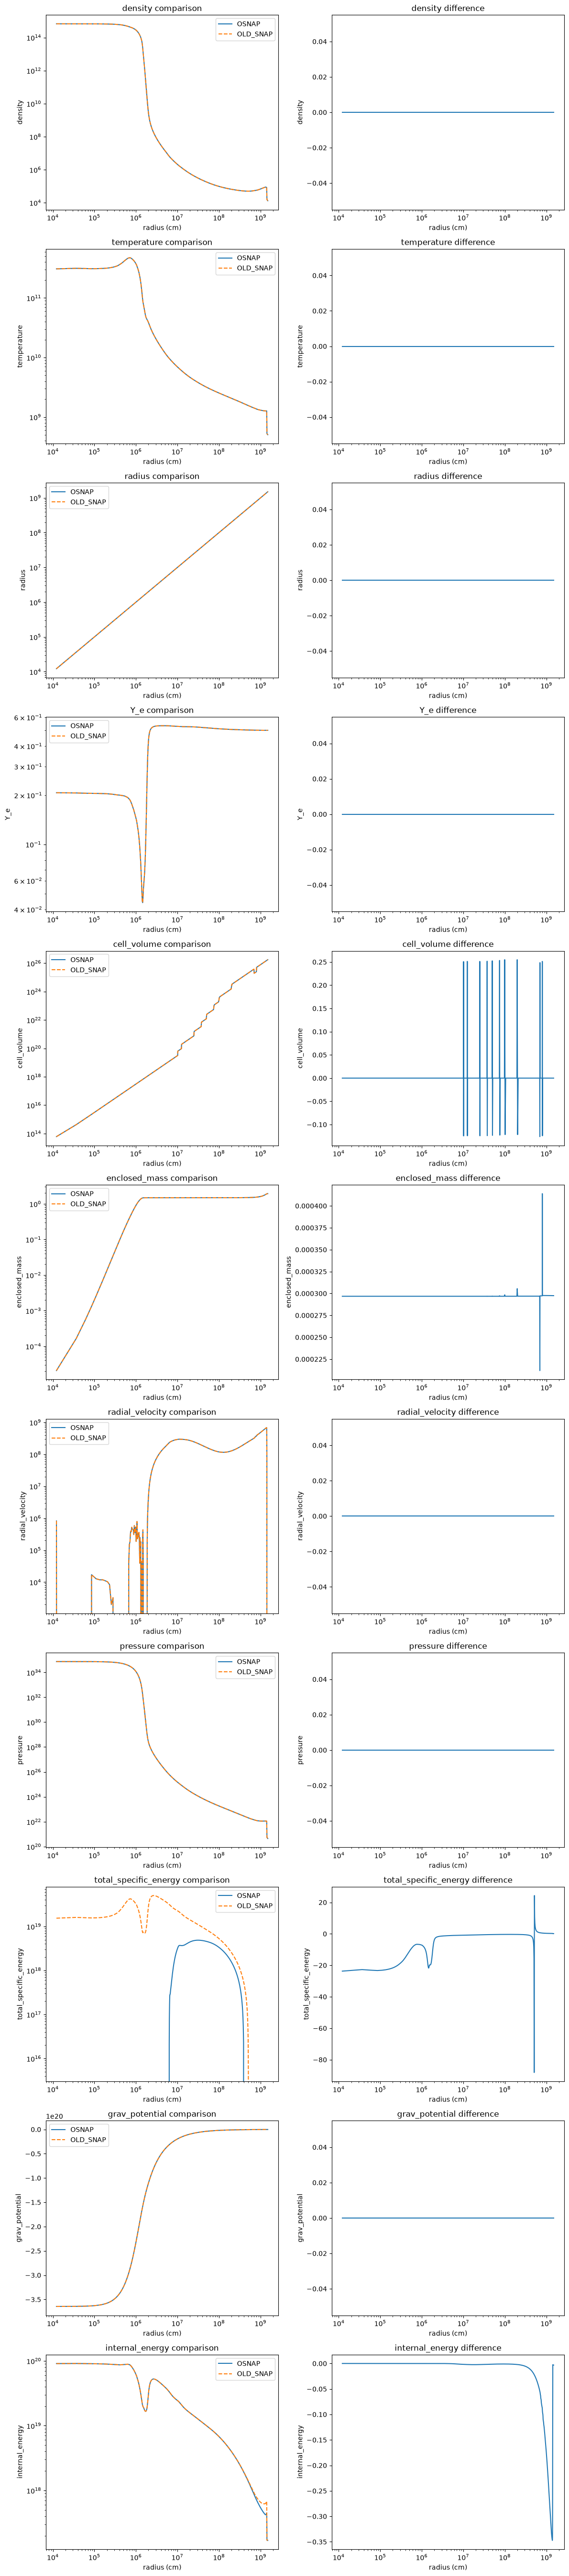

In [ ]:
stir_ds = yt.load("/mnt/research/SNAPhU/STIR/run_sukhbold/run_14may19_a1.25/run_12.0/output/stir2_14may19_s12.0_alpha1.25_hdf5_chk_0197")
stir_data = stir_ds.all_data()
needed_profiles = [("gas", "density"), ("flash", "temp"), ("gas", "r"), ("flash", "velx"), ("gas", "pressure"), ("flash", "ye  "),
            ("flash", "cell_volume"), ("flash", "ener"), ("flash", "gpot")]
old_data = stir_data.to_dataframe(needed_profiles)

old_data = old_data.assign(enclosed_mass = np.cumsum(old_data['cell_volume'].values * old_data['density'].values) / 1.989E33)
total_specific_energy = test_calculate_total_specific_energy(True, old_data['ye  '].values, old_data['temp'].values, old_data['density'].values, old_data['velx'].values, old_data['gpot'].values)
old_data = old_data.assign(total_specific_energy = total_specific_energy)

data = odb.ODB("/mnt/home/jdelker/test1.odb")

name_sets = [["density", "density", True, True],
         ["temperature", "temp", True, True],
         ["radius", "r", True, True],
         ["Y_e", "ye  ", True, True],
         ["cell_volume", "cell_volume", True, True],
         ["enclosed_mass", "enclosed_mass", True, True],
         ["radial_velocity", "velx", True, True],
         ["pressure", "pressure", True, True],
         ["total_specific_energy", "total_specific_energy", True, True],
         ["grav_potential", "gpot", True, False],
         ["internal_energy", "ener", True, True]]

osnap_radius = data.read("profiles", "radius").value
old_radius = old_data["r"].values
old_radius = old_radius[(old_radius >= osnap_radius.min()) & (old_radius <= osnap_radius.max())]
old_data = old_data[old_data["r"].isin(old_radius)]

osnap_radius_adj = osnap_radius[(osnap_radius >= old_radius.min()) & (osnap_radius <= old_radius.max())]

plt.figure(figsize=(12, 54))
for i in range(len(name_sets)):
    name_set = name_sets[i]
    osnap_data = data.read("profiles", name_set[0]).value
    osnap_data = osnap_data[(osnap_radius >= old_radius.min()) & (osnap_radius <= old_radius.max())]
    
    plt.subplot(11, 2, (i * 2) + 1)
    plt.title(f"{name_set[0]} comparison")
    plt.plot(osnap_radius_adj, osnap_data, label = "OSNAP")
    plt.plot(old_radius, old_data[name_set[1]].values, "--", label = "OLD_SNAP")
    plt.xlabel("radius (cm)")
    plt.ylabel(name_set[0])
    plt.legend()
    
    if name_set[2]:
        plt.xscale("log")
    if name_set[3]:
        plt.yscale("log")
    
    plt.subplot(11, 2, (i * 2) + 2)
    plt.title(f"{name_set[0]} difference")
    interp_func = interp1d(old_radius, old_data[name_set[1]].values)
    values = interp_func(osnap_radius_adj)
    plt.plot(osnap_radius_adj, (osnap_data - values) / values)
    plt.xlabel("radius (cm)")
    plt.ylabel(name_set[0] + " error")
    plt.semilogx()

plt.tight_layout()
plt.show()
